In [2]:
words = open('names.txt', 'r').read().splitlines()

In [4]:
len(words)

847860

In [5]:
import torch

In [7]:
N = torch.zeros((27, 27), dtype=torch.int32)

In [14]:
import string
chars = ['.'] +list(string.ascii_lowercase) # ['.', a, b, c, d, e, f, g, h, i, j, k, l, m, n, o, p, q, r, s, t, u, v, w, x, y, z]
string_to_index = {ch:i for i, ch in enumerate(chars)} # {'.': 0, 'a': 1, 'b': 2, ..., 'z': 26}
index_to_string = {i:ch for i, ch in enumerate(chars)} # {0: '.', 1: 'a', 2: 'b', ..., 26: 'z'}

In [ ]:
# 앞 문자와 뒷 문자를 카운트하여 N 행렬에 저장한다.
for w in words:
  chs = ['.'] + list(w) + ['.']  # . + w: w로 시작하는 이름 / w + .: w로 끝나는 이름
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = string_to_index[ch1]
    ix2 = string_to_index[ch2]
    N[ix1, ix2] += 1

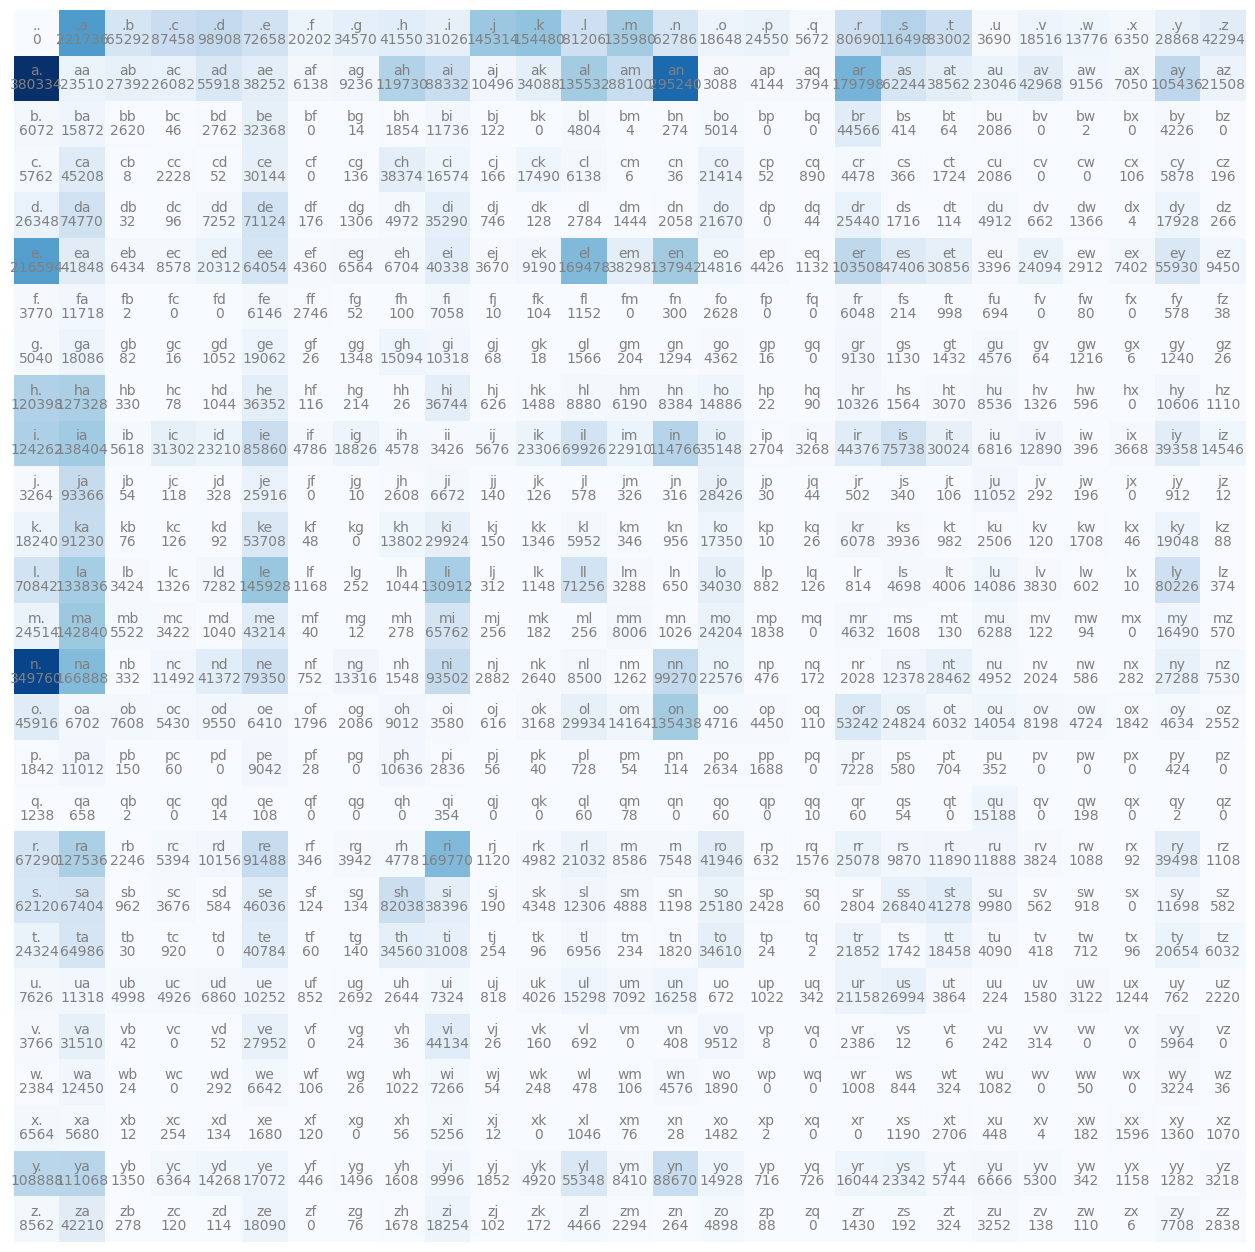

In [18]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = index_to_string[i] + index_to_string[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

In [23]:
N[0]

tensor([     0, 221736,  65292,  87458,  98908,  72658,  20202,  34570,  41550,
         31026, 145314, 154480,  81206, 135980,  62786,  18648,  24550,   5672,
         80690, 116498,  83002,   3690,  18516,  13776,   6350,  28868,  42294],
       dtype=torch.int32)

In [ ]:
# P = N.float()
P = (N + 1).float() # 위의 표를 보면, 'zq', 'fp' 와 같이 카운트가 0인 것들이 있음. 이걸 그대로 사용해서 추후 아래에서 nll을 구할 때, 저 문자열을 갖고 있는 이름이 실제 나타나면 nll 값이 inf로 나온다. log 0 = -inf. 이를 막기 위해 + 1을 함. model smoothing의 개념. 크게 더할 수록 편차들이 줄어든다.

# Count 기반 Bigram. 관찰된 빈도를 확률로 변환한다.
# sum(0, keepdim=True)로 하면 열 합계가 1이 됨, sum(1, keepdim=True)로 하면 행 합계가 1이 됨. 우리가 구하고자 하는 것은 앞 문자가 주어졌을 때 뒷 문자가 나올 확률이므로, 행 합계가 1이 되도록 해야 함.
# keepdim=True를 하지 않으면 P /= P.sum(1)에서 P.sum(1)의 shape이 (27,)이 되어 P의 shape (27, 27)과 broadcasting시 (1, 27)으로 변환되어 의도와 다른 결과가 나옴.
P /= P.sum(1, keepdim=True)

In [32]:
g = torch.Generator().manual_seed(2147483647)  # 이건 고정값 나오도록 사용함

# 확률 분포를 기반으로 이름을 생성한다.
for i in range(10):
  out = []
  ix = 0
  while True:
    p = P[ix]
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(index_to_string[ix])
    if ix == 0:
      break
  print(''.join(out))

dexze.
momakurailezityha.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


In [ ]:
# GOAL: maximize likelihood of the data w.r.t. model parameters (statistical modeling)
# equivalent to maximizing the log likelihood (because log is monotonic)
# equivalent to minimizing the negative log likelihood
# equivalent to minimizing the average negative log likelihood

'''
a, b, c가 발생하는 확률을 고려할 때, a, b, c가 동시에 발생할 확률은 P(a, b, c) = P(a) * P(b) * P(c)로 계산할 수 있다.
헌데, 확률을 * 연산하여 사용하면 값이 작아져서 정밀도 문제가 발생할 수 있다. 따라서 log 특성을 이용한다.

log(a*b*c) = log(a) + log(b) + log(c)
'''


In [ ]:
'''
likelihood? 모델이 실제 데이터에 부여한 확률.
'''

log_likelihood = 0.0  # 확률의 곱을 로그의 합으로 계산
n = 0

# for w in ['jungbum']: # 내 이름으로 했더니 nll이 높아진다
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = string_to_index[ch1]  # 현재 문자
    ix2 = string_to_index[ch2]  # 다음 문자
    prob = P[ix1, ix2]  # P: 현재 문자가 주어졌을 때 다음 문자가 나올 확률 행렬, prob: 현재 문자가 주어졌을 때 다음 문자가 나올 확률
    logprob = torch.log(prob) # log(x) from 0 to 1. y: - infinity to 0. https://www.wolframalpha.com/input?i=log%28x%29+from+0+to+1
    log_likelihood += logprob
    n += 1
    # print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')  # logprob 확인. 건 수가 너무 많아서 깃에 안올라가서 주석처리함.

  # print(f'{log_likelihood=}')
nll = -log_likelihood  # nll: negative log likelihood
print(f'{nll=}')
print(f'{nll/n}') # log_likelihood 이 높을 수록 좋은 모델이니, nll은 낮을 수록 좋다. 